# 30｜七格至少五格与未知状态

目标：把业务规则写成不会悄悄“误绿”的代码。先看真实焊缝，然后用合成七格示意验证逻辑。**当前公开照片没有电池七格真值，本课没有训练七格识别器。**

正确顺序是汇流排定位 → 镍片存在性 → 镍片/焊纹对齐 → 七格可见性与外观判定 → 规则。七格中至少五格符合人工确认的外观标准才可能绿；本课采用保守策略，任一格看不清先黄，完整清晰但不足五格红。缺镍片确认后红。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 20844 (\N{CJK UNIFIED IDEOGRAPH-516C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 24320 (\N{CJK UNIFIED IDEOGRAPH-5F00}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 28938 (\N{CJK UNIFIED IDEOGRAPH-710A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

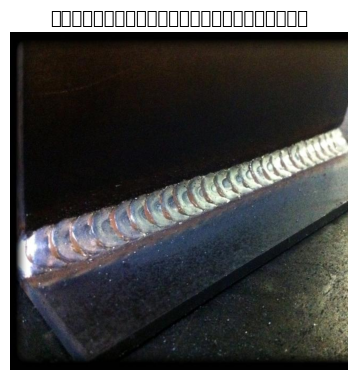

In [2]:
lab.show_images([lab.load_case("weld_good")],
                ["真实公开焊缝：类别语义不同，没有刀片电池七格标签"], cols=1)

## 1. 合成示意只用于规则

下面画的条纹不是实际焊点。七格沿着对齐后的焊接排布方向编号，而不是随意把整张图片平均切成七份。真实系统需要从镍片窗口剔除柱子、背景、强反光和边界后确定格位。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 35268 (\N{CJK UNIFIED IDEOGRAPH-89C4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 21017 (\N{CJK UNIFIED IDEOGRAPH-5219}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 31034 (\N{CJK UNIFIED IDEOGRAPH-793A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

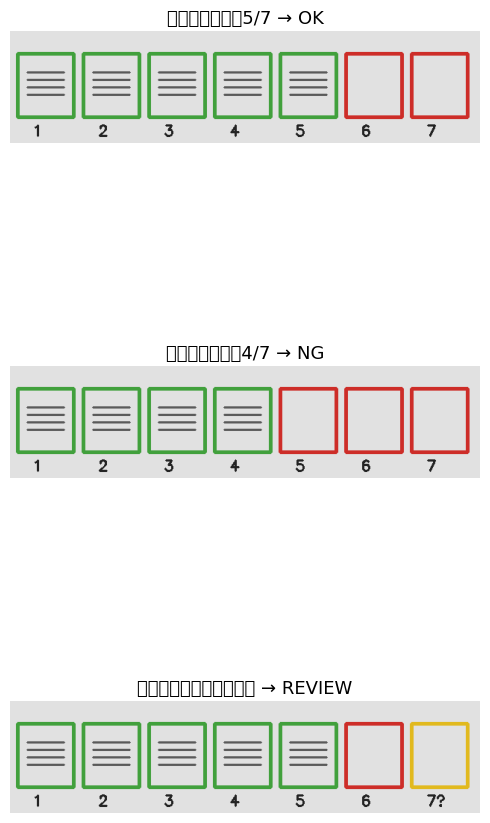

In [3]:
def schematic(slots):
    canvas = np.full((150, 630, 3), 225, np.uint8)
    colors = {"OK": (60, 160, 65), "NG": (40, 45, 205), None: (30, 185, 225)}
    for index, state in enumerate(slots):
        left = 10 + index * 88
        cv2.rectangle(canvas, (left, 30), (left + 75, 115), colors[state], 3)
        if state == "OK":
            for y in [55, 65, 75, 85]: cv2.line(canvas, (left + 13, y), (left + 62, y), (90, 90, 90), 2)
        cv2.putText(canvas, str(index + 1) + ("?" if state is None else ""), (left + 20, 140),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (35, 35, 35), 2)
    return canvas

examples = [["OK"] * 5 + ["NG"] * 2, ["OK"] * 4 + ["NG"] * 3,
            ["OK"] * 5 + ["NG", None]]
lab.show_images([schematic(slots) for slots in examples],
                ["合成规则示意：5/7 → OK", "合成规则示意：4/7 → NG", "合成规则示意：未知一格 → REVIEW"], cols=1)

## 2. 运行规则和异常输入

未知不能用 0.5 概率或文件名强行填补。缺片、出画、不可判、少于七格都要明确原因。二维外观 OK 仅表示满足本规则，不等于内部熔合或机械强度达标。

In [4]:
cases = [
    ("清晰5格", examples[0], {}, "OK"),
    ("清晰4格", examples[1], {}, "NG"),
    ("仍有未知", examples[2], {}, "REVIEW"),
    ("确认缺镍片", [], {"nickel_present": False}, "NG"),
    ("镍片未知", ["OK"] * 7, {"nickel_present": None}, "REVIEW"),
    ("仅有六格", ["OK"] * 6, {}, "REVIEW"),
    ("工件出画", ["OK"] * 7, {"busbar_visible": False}, "REVIEW"),
    ("画质差", ["OK"] * 7, {"quality_clear": False}, "REVIEW"),
]
for name, slots, options, expected in cases:
    result = lab.seven_slot_verdict(slots, **options)
    print(name, result["status"], result["reason"])
    assert result["status"] == expected, name

清晰5格 OK 七格外观中5格符合已确认标准
清晰4格 NG 七格外观中4格符合已确认标准
仍有未知 REVIEW 七格未全部清晰判读，未知不能自动填为合格
确认缺镍片 NG 已确认缺少镍片
镍片未知 REVIEW 镍片存在性未知
仅有六格 REVIEW 七格未全部清晰判读，未知不能自动填为合格
工件出画 REVIEW 工件不完整或画质不满足判读条件
画质差 REVIEW 工件不完整或画质不满足判读条件


## 3. 别把坐标单位混起来

先记录整帧尺寸，再记录局部 ROI 的原图坐标。检测输入若缩放/补边，必须把框映射回原图；分格处理使用 ROI 自己的宽高。下面用简单数值展示矩形窗口转换，不宣称该窗口是实际电池镍片。

In [5]:
frame_width, frame_height = 1920, 1080
roi = [600, 300, 210, 70]  # xywh 原图像素，纯坐标示例
normalized = [roi[0] / frame_width, roi[1] / frame_height,
              roi[2] / frame_width, roi[3] / frame_height]
restored = np.array(normalized) * np.array([frame_width, frame_height, frame_width, frame_height])
assert np.allclose(restored, roi)
print("归一化 xywh", normalized)
print("ROI 七格边界（只有对齐后才有业务意义）", np.linspace(roi[0], roi[0] + roi[2], 8).tolist())

归一化 xywh [0.3125, 0.2777777777777778, 0.109375, 0.06481481481481481]
ROI 七格边界（只有对齐后才有业务意义） [600.0, 630.0, 660.0, 690.0, 720.0, 750.0, 780.0, 810.0]


## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。